# Gemini 및 LangGraph를 사용하여 처음부터 ReAct 에이전트 만들기

https://ai.google.dev/gemini-api/docs/langgraph-example?hl=ko


LangGraph는 상태 저장 LLM 애플리케이션을 빌드하기 위한 프레임워크이므로 ReAct (추론 및 행동) 에이전트를 구성하는 데 적합합니다.

ReAct 에이전트는 LLM 추론과 작업 실행을 결합합니다. 사용자 목표를 달성하기 위해 반복적으로 생각하고 도구를 사용하며 관찰에 따라 행동하여 접근 방식을 동적으로 조정합니다. '"ReAct: Synergizing Reasoning and Acting in Language Models"'(2023)에서 소개된 이 패턴은 엄격한 워크플로를 통해 인간과 유사한 유연한 문제 해결을 반영하려고 합니다.

LangGraph는 ReAct 구현에 더 많은 제어 및 맞춤설정이 필요한 경우에 유용한 사전 빌드된 ReAct 에이전트 ( create_react_agent)를 제공합니다. 이 가이드에서는 간소화된 버전을 보여줍니다.

LangGraph는 세 가지 주요 구성요소를 사용하여 에이전트를 그래프로 모델링합니다.

State: 애플리케이션의 현재 스냅샷을 나타내는 공유 데이터 구조 (일반적으로 TypedDict 또는 Pydantic BaseModel).
Nodes: 에이전트의 로직을 인코딩합니다. 현재 상태를 입력으로 받고 일부 계산 또는 부작용을 실행하며 LLM 호출 또는 도구 호출과 같은 업데이트된 상태를 반환합니다.
Edges: 현재 State를 기반으로 실행할 다음 Node를 정의하여 조건부 로직 및 고정 전환을 허용합니다.

# 세팅

In [4]:
! uv pip install langgraph langchain-google-genai geopy requests

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Resolved 46 packages in 304ms
Prepared 4 packages in 345ms
Uninstalled 2 packages in 18ms
Installed 4 packages in 424ms
 + geographiclib==2.1
 + geopy==2.4.1
 - google-auth==2.43.0
 + google-auth==2.55.1
 - google-genai==1.49.0
 + google-genai==2.10.0


 GEMINI_API_KEY에서 API 키를 설정

In [9]:
import os

# Read your API key from the environment variable or set it manually
api_key = os.getenv("GOOGLE_API_KEY")

# State

LangGraph를 사용하여 ReAct 에이전트를 구현하는 방법을 더 잘 이해할 수 있도록 이 가이드에서는 실제 예시를 안내합니다. 목표가 도구를 사용하여 지정된 위치의 현재 날씨를 찾는 에이전트를 만듭니다.

이 날씨 에이전트의 경우 State는 진행 중인 대화 기록(메시지 목록)과 수행된 단계 수의 카운터(정수)를 유지합니다(설명을 위해).

LangGraph는 상태 메시지 목록을 업데이트하기 위한 도우미 함수 add_messages를 제공합니다. 현재 목록과 새 메시지를 가져와 결합된 목록을 반환하는 리듀서 역할을 합니다. 메시지 ID별로 업데이트를 처리하고 기본적으로 새 메시지에는 '추가 전용' 동작을 사용합니다.

In [17]:
from typing import Annotated, Sequence, TypedDict

from langchain_core.messages import BaseMessage
from langgraph.graph.message import add_messages  # 상태(state)에 메시지를 추가해주는 헬퍼 함수(reducer)


class AgentState(TypedDict):
    """에이전트의 상태(State)를 정의하는 스키마.

    LangGraph에서는 그래프의 State를 TypedDict, dataclass, 또는 Pydantic BaseModel로 정의할 수 있는데,
    TypedDict가 가장 널리 쓰이는 방식임(런타임 오버헤드가 없고 체크포인팅 등 기능과 잘 맞물림).
    """

    # 대화 메시지 목록.
    # Annotated[Sequence[BaseMessage], add_messages]에서 add_messages는 "리듀서(reducer)" 역할을 함.
    # 리듀서가 없으면 노드가 반환한 값이 기존 값을 그냥 덮어써버리지만,
    # add_messages를 지정하면 새 메시지를 기존 리스트 끝에 "추가(append)"하는 방식으로 병합됨.
    # (참고로 같은 id를 가진 메시지가 들어오면 덮어쓰기(교체)로 처리됨)
    messages: Annotated[Sequence[BaseMessage], add_messages]

    # 에이전트가 지금까지 수행한 스텝(단계) 수.
    # 리듀서가 지정되지 않았으므로 노드가 이 값을 반환하면 기존 값을 그대로 덮어씀(overwrite).
    number_of_steps: int

# 날씨 도구를 정의

In [18]:
from langchain_core.tools import tool
from geopy.geocoders import Nominatim
from pydantic import BaseModel, Field
import requests

# Nominatim(OpenStreetMap 기반 무료 지오코딩 서비스) 클라이언트 생성
# user_agent는 Nominatim 사용 정책상 필수 값(고유 식별자 역할)
geolocator = Nominatim(user_agent="weather-app")


class SearchInput(BaseModel):
    """get_weather_forecast 툴의 입력 스키마.

    @tool 데코레이터에 args_schema로 전달하면, 함수 시그니처만으로 스키마를
    자동 추론하는 대신 이 Pydantic 모델을 기준으로 LLM에게 인자 설명(description)을
    명시적으로 제공할 수 있음.
    """
    location: str = Field(description="The city and state, e.g., San Francisco")
    date: str = Field(description="the forecasting date for when to get the weather format (yyyy-mm-dd)")


# return_direct=True: 이 툴이 호출되면 결과가 LLM을 다시 거치지 않고
# 호출자(에이전트 루프)에게 바로 반환됨. 즉 LLM이 이 결과를 요약/가공/재작성하지 않음.
# -> 날씨 데이터처럼 "이미 완성된 결과"를 그대로 보여줘도 되는 경우에 적합.
# 참고로 여러 툴이 한 턴에 동시 호출되면, return_direct는 호출된 모든 툴이
# return_direct=True일 때만 적용됨(공식 문서 기준).
@tool("get_weather_forecast", args_schema=SearchInput, return_direct=True)
def get_weather_forecast(location: str, date: str):
    """Retrieves the weather using Open-Meteo API.
    Takes a given location (city) and a date (yyyy-mm-dd).
    Returns:
        A dict with the time and temperature for each hour.
    """
    # Note that Colab may experience rate limiting on this service. If this
    # happens, use a machine to which you have exclusive access.

    # 도시명(location) 문자열을 위도/경도로 변환(지오코딩)
    # 주의: 이 geocode() 호출 자체는 try/except로 감싸져 있지 않음.
    # Nominatim 서버가 타임아웃되거나 네트워크 오류가 나면 여기서 예외가 그대로 터짐
    # (아래 except는 requests.get 이후 블록만 감쌈)
    location = geolocator.geocode(location)

    if location:
        try:
            # Open-Meteo 무료 API 호출(별도 API 키 불필요)
            # hourly=temperature_2m: 지상 2m 기준 시간별 기온 데이터를 요청
            response = requests.get(
                f"https://api.open-meteo.com/v1/forecast?"
                f"latitude={location.latitude}&longitude={location.longitude}"
                f"&hourly=temperature_2m&start_date={date}&end_date={date}"
            )
            data = response.json()

            # 응답의 "time" 리스트와 "temperature_2m" 리스트를
            # zip으로 짝지어 {시간: 온도} 형태의 딕셔너리로 변환
            return dict(zip(data["hourly"]["time"], data["hourly"]["temperature_2m"]))
        except Exception as e:
            # API 호출 실패, JSON 파싱 실패, 혹은 data["hourly"] 키가 없는 경우 등을 포괄적으로 처리
            return {"error": str(e)}
    else:
        # 지오코딩 결과가 없을 때(예: 존재하지 않는 지명, 오타 등)
        return {"error": "Location not found"}


tools = [get_weather_forecast]

# 모델을 초기화하고 도구를 모델에 바인딩

In [19]:
from datetime import datetime
from langchain_google_genai import ChatGoogleGenerativeAI

# LLM 클래스 생성
llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=1.0,       # 값이 높을수록(0~2 범위) 더 창의적/무작위한 답변을 생성
    max_retries=2,         # API 호출 실패 시 최대 재시도 횟수
    google_api_key=api_key,  # Gemini API 키 (환경변수 GOOGLE_API_KEY 또는 GEMINI_API_KEY로 대체 가능)
)

# 모델에 tools를 바인딩(연결)
# bind_tools()는 원본 llm 객체를 수정하지 않고, tools 정보가 포함된 새로운 Runnable을 반환함
# 이렇게 하면 모델이 응답할 때 필요하다고 판단되면 get_weather_forecast를 호출하는
# tool_calls를 포함한 메시지를 생성할 수 있게 됨
model = llm.bind_tools([get_weather_forecast])

# tools가 연결된 모델을 테스트로 호출
# invoke()에 문자열을 넘기면 내부적으로 HumanMessage로 감싸져 처리됨
res = model.invoke(f"What is the weather in Berlin on {datetime.today()}?")

print(res)

content='' additional_kwargs={'function_call': {'name': 'get_weather_forecast', 'arguments': '{"location": "Berlin", "date": "2026-07-07"}'}, '__gemini_function_call_thought_signatures__': {'b77f20ab-6b52-4fc2-8562-1fda87a11cf3': 'CvMDARFNMg/86DbB27jusyqOpCBg2CxtiVpAfghQF66J58cU8H21nRVT/TWyDl2MDnpwKWL+x+w3jrUekqZibVx13vnyKs8+pDN9g6cLGP/3gvDIilf9eT7p+Is6PMJQZk2LPob/2eyphgqmrkeO/C+l1rNAv3PcZFCCs4XlE76MKfDRr90H1yG6GSXTWt2lgRYceykpyCDX7yoV99QiVDyzGXSrPVnoD/WQ9yjxFM360Idzs5W9Bz7pAp7Gj6oSIyCHHwUPLz91uuAYshnX8ROAtbbOKczj93bQKEDh/wiImwG1apeTwGUtLmpN9y3vOv8wL6wNdbRRYLJiETd4nBmm1tnCRqfC9udc5fpOeEchHv3hVF3kiEKnw1ly7f/rdBlSp4z1IrS+Nun3G8QOI9KqQk/5+vL3ad0RgGBmq4qaM+tyoicyeDuOFTGwtzeoB17wsSIqlxlfSvZUMzIhF+fy+dJjg/aor3a8C2qWlBtwdUXTWYNluDKCmX+NXp3SEI0TFOSs6BpNlxhMtzyNORYUm6XSgAbFHgF7E7pxbT226pMGoLvhJZ5DDeTMMxvHurl/MQI6L6VcM+lJ0aBU8th/yh3MEw405fb300EG5CEczd8gh9zXHXwk91imhpmhRq9kMriSEhHmACePUcwijYydYaKBXw=='}} response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings

# 모든 에이전트 구성요소가 준비되면 이제 이를 조합

tools 만들기

In [20]:
from langchain_core.messages import ToolMessage
from langchain_core.runnables import RunnableConfig

# 툴 이름(name) -> 툴 객체를 매핑하는 딕셔너리
# tool_call["name"]으로 실제 실행할 툴 객체를 빠르게 찾기 위한 용도
tools_by_name = {tool.name: tool for tool in tools}


# 툴 노드 정의 (그래프에서 실제로 도구를 실행하는 노드)
def call_tool(state: AgentState):
    outputs = []
    # 마지막 메시지(보통 모델이 방금 응답한 AIMessage)에 담긴 tool_calls를 순회
    # 모델이 한 번에 여러 툴을 호출하도록 요청했을 수도 있으므로 반복 처리함
    for tool_call in state["messages"][-1].tool_calls:
        # 이름으로 해당 툴 객체를 찾아 invoke()로 실제 실행
        # tool_call["args"]는 모델이 생성한 인자(dict)이며, args_schema(SearchInput)에 따라 검증됨
        tool_result = tools_by_name[tool_call["name"]].invoke(tool_call["args"])
        outputs.append(
            ToolMessage(
                content=tool_result,
                name=tool_call["name"],
                # tool_call_id를 반드시 넣어야 함:
                # 모델이 "이 tool_call_id에 대한 응답이 왔다"는 것을 인식하는 데 필요
                tool_call_id=tool_call["id"],
            )
        )
    # 반환된 messages 리스트는 AgentState의 add_messages 리듀서에 의해
    # 기존 messages 리스트 뒤에 append됨(덮어쓰기 아님)
    return {"messages": outputs}


def call_model(
    state: AgentState,
    config: RunnableConfig,  # 콜백, 태그, 메타데이터 등 실행 설정 정보를 담는 LangChain 표준 객체
):
    # 시스템 프롬프트(있다면)와 전체 대화 메시지(state["messages"])를 모델에 전달해 호출
    # 여기서 model은 이전 단계에서 llm.bind_tools([...])로 만든, 툴이 연결된 모델
    response = model.invoke(state["messages"], config)
    # 이 함수는 리스트를 반환하며, 이는 AgentState의 messages 필드에 지정된
    # add_messages 리듀서를 통해 기존 상태(state)의 메시지 리스트와 합쳐짐(append)
    return {"messages": [response]}


# 계속 진행할지(tool 호출) 아니면 종료할지를 결정하는 조건부 엣지(edge) 함수
def should_continue(state: AgentState):
    messages = state["messages"]
    # 마지막 메시지에 tool_calls가 없다면 (즉 모델이 최종 답변을 했다면) 종료
    if not messages[-1].tool_calls:
        return "end"
    # tool_calls가 있다면 기본적으로 계속 진행(툴 실행 노드로 이동)
    return "continue"

In [21]:
from langgraph.graph import StateGraph, END

# AgentState 스키마를 기반으로 새로운 그래프(workflow) 생성
workflow = StateGraph(AgentState)

# 1. 노드 추가
# 첫 번째 인자는 노드 이름(문자열), 두 번째 인자는 해당 노드가 호출될 때 실행할 함수
workflow.add_node("llm", call_model)
workflow.add_node("tools", call_tool)

# 2. 진입점(entry point)을 "llm" 노드로 설정
# 즉 그래프가 실행되면 가장 먼저 call_model이 호출됨
# 참고: set_entry_point("llm")은 사실상 add_edge(START, "llm")과 동일한 동작을 함
workflow.set_entry_point("llm")

# 3. "llm" 노드가 호출된 뒤 실행될 조건부 엣지(conditional edge) 추가
workflow.add_conditional_edges(
    # 이 엣지는 "llm" 노드를 빠져나갈 때(실행 완료 후) 동작함
    "llm",
    # 다음에 어떤 노드로 갈지 결정하는 함수 (앞서 정의한 should_continue)
    should_continue,
    # 매핑 딕셔너리: should_continue 함수의 반환값(문자열)을 key로,
    # 실제로 이동할 노드 이름을 value로 지정
    # END는 그래프 실행이 끝났음을 나타내는 특수 노드
    {
        # should_continue가 "continue"를 반환하면 "tools" 노드로 이동
        "continue": "tools",
        # 그 외("end")에는 그래프 종료
        "end": END,
    },
)

# 4. "tools" 노드가 호출된 뒤에는 조건 없이 항상 "llm" 노드로 돌아가는 일반 엣지 추가
# 이렇게 하면 "llm" -> (조건에 따라) "tools" -> "llm" -> ... 형태의 루프(ReAct 패턴)가 만들어짐
workflow.add_edge("tools", "llm")

# 그래프를 컴파일(compile)하여 실행 가능한 CompiledStateGraph 객체로 변환
# compile() 전까지 workflow는 그저 "설계도"일 뿐이며, invoke()/stream() 등을 호출할 수 없음
graph = workflow.compile()

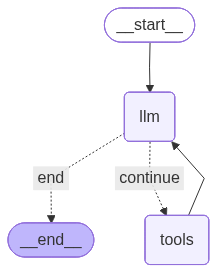

In [22]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

# 이제 에이전트를 실행합니다.

In [23]:
from datetime import datetime

# 그래프에 넣을 초기 입력(inputs) 딕셔너리 생성
# AgentState의 "messages" 필드에 해당하는 값을 채워줌
# ("user", "내용") 형태의 튜플은 LangChain이 내부적으로 HumanMessage로 자동 변환해줌
inputs = {"messages": [("user", f"What is the weather in Berlin on {datetime.today()}?")]}

# stream_mode="values"로 그래프를 스트리밍 실행하며 각 단계를 확인
# stream_mode="values": 노드가 하나 실행 완료될 때마다 "전체 상태(state)"를 통째로 반환
# (참고로 stream_mode="updates"를 쓰면 전체가 아니라 "변경된 부분만" 반환됨)
for state in graph.stream(inputs, stream_mode="values"):
    # 매 스텝마다 반환된 state의 messages 리스트 중 가장 마지막 메시지를 꺼냄
    last_message = state["messages"][-1]
    # pretty_print()는 BaseMessage 계열 객체에 내장된 메서드로,
    # 메시지 타입(Human/AI/Tool)과 내용을 보기 좋게 콘솔에 출력해줌
    last_message.pretty_print()

================================ Human Message =================================

What is the weather in Berlin on 2026-07-07 11:48:35.106320?
================================== Ai Message ==================================
Tool Calls:
  get_weather_forecast (2cf72142-3ced-4533-b3be-3d7e19912580)
 Call ID: 2cf72142-3ced-4533-b3be-3d7e19912580
  Args:
    location: Berlin
    date: 2026-07-07
================================= Tool Message =================================
Name: get_weather_forecast

{'2026-07-07T00:00': 18.7, '2026-07-07T01:00': 18.3, '2026-07-07T02:00': 18.0, '2026-07-07T03:00': 17.8, '2026-07-07T04:00': 17.6, '2026-07-07T05:00': 17.7, '2026-07-07T06:00': 18.1, '2026-07-07T07:00': 18.6, '2026-07-07T08:00': 18.3, '2026-07-07T09:00': 18.3, '2026-07-07T10:00': 18.5, '2026-07-07T11:00': 19.0, '2026-07-07T12:00': 20.0, '2026-07-07T13:00': 20.1, '2026-07-07T14:00': 20.0, '2026-07-07T15:00': 20.1, '2026-07-07T16:00': 20.3, '2026-07-07T17:00': 19.6, '2026-07-07T18:00': 19.0, '

In [16]:
state["messages"].append(("user", "Would it be warmer in Munich?"))

for state in graph.stream(state, stream_mode="values"):
    last_message = state["messages"][-1]
    last_message.pretty_print()

================================ Human Message =================================

Would it be warmer in Munich?
================================== Ai Message ==================================
Tool Calls:
  get_weather_forecast (41900dd2-f748-400d-b66a-16547b2f4933)
 Call ID: 41900dd2-f748-400d-b66a-16547b2f4933
  Args:
    date: 2026-07-07
    location: Munich
================================= Tool Message =================================
Name: get_weather_forecast

{'2026-07-07T00:00': 20.4, '2026-07-07T01:00': 19.6, '2026-07-07T02:00': 19.2, '2026-07-07T03:00': 18.7, '2026-07-07T04:00': 18.6, '2026-07-07T05:00': 19.2, '2026-07-07T06:00': 20.6, '2026-07-07T07:00': 22.5, '2026-07-07T08:00': 24.3, '2026-07-07T09:00': 25.8, '2026-07-07T10:00': 27.2, '2026-07-07T11:00': 28.0, '2026-07-07T12:00': 28.5, '2026-07-07T13:00': 28.6, '2026-07-07T14:00': 28.4, '2026-07-07T15:00': 29.1, '2026-07-07T16:00': 29.2, '2026-07-07T17:00': 28.9, '2026-07-07T18:00': 27.9, '2026-07-07T19:00': 26.2, '2026-